# Bank Marketing — Baseline Modeling

## 1. Introduction

This notebook trains and evaluates a Logistic Regression baseline for ranking
term-deposit subscription records.

- Use the established chronological Train/Validation split.
- Exclude `duration` and represent the `pdays = 999` sentinel explicitly.
- Fit preprocessing and the estimator on Train only.
- Evaluate Validation with AP, ROC-AUC, and Top-K metrics.
- Keep Test frozen for final evaluation.

## 2. Data & Pipeline Setup

Load the raw data in source order and prepare only Train and Validation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    average_precision_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "bank-additional"
    / "bank-additional-full.csv"
)

df = pd.read_csv(RAW_DATA_PATH, sep=";")

train_end = int(len(df) * 0.70)
valid_end = int(len(df) * 0.90)
train_df = df.iloc[:train_end].copy()
valid_df = df.iloc[train_end:valid_end].copy()

In [2]:
target = "y"
excluded_features = ["duration"]
modeling_features = [
    column for column in df.columns
    if column not in [target, *excluded_features]
]

X_train = train_df[modeling_features].copy()
X_valid = valid_df[modeling_features].copy()

target_mapping = {"no": 0, "yes": 1}
y_train = train_df[target].map(target_mapping)
y_valid = valid_df[target].map(target_mapping)

pd.DataFrame(
    {
        "rows": [len(X_train), len(X_valid)],
        "features": [X_train.shape[1], X_valid.shape[1]],
        "positive_rate": [y_train.mean(), y_valid.mean()],
    },
    index=["Train", "Validation"],
)

,rows,features,positive_rate
Train,28831,19,0.055704
Validation,8238,19,0.138626


### 2.1 Sentinel-Aware Preprocessing

The Pipeline scales eight ordinary numerical features, one-hot encodes ten
categorical features, and replaces raw `pdays` with:

- `pdays_previously_contacted`: whether `pdays != 999`
- `pdays_elapsed`: elapsed days for contacted records, otherwise `0`

In [3]:
numeric_features = [
    "age",
    "campaign",
    "previous",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome",
]


def split_pdays(values):
    pdays = np.asarray(values).reshape(-1)
    previously_contacted = (pdays != 999).astype(float)
    elapsed_days = np.where(pdays == 999, 0.0, pdays.astype(float))
    return np.column_stack([previously_contacted, elapsed_days])


def pdays_feature_names(transformer, input_features):
    return np.asarray(
        ["pdays_previously_contacted", "pdays_elapsed"],
        dtype=object,
    )

In [4]:
pdays_transformer = Pipeline(
    steps=[
        (
            "derive",
            FunctionTransformer(
                split_pdays,
                validate=False,
                feature_names_out=pdays_feature_names,
            ),
        ),
        ("scale", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        ),
        ("pdays", pdays_transformer, ["pdays"]),
    ],
    remainder="drop",
)

baseline_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000)),
    ]
)

## 3. Baseline Training

Fit the complete Pipeline on Train and generate positive-class scores for
Validation. Validation is transformed with the preprocessing learned from
Train; it is not used during fitting.

In [5]:
baseline_pipeline.fit(X_train, y_train)
y_valid_score = baseline_pipeline.predict_proba(X_valid)[:, 1]

fitted_model = baseline_pipeline.named_steps["model"]
pd.Series(
    {
        "optimization_iterations": fitted_model.n_iter_[0],
        "transformed_features": fitted_model.n_features_in_,
        "validation_scores": len(y_valid_score),
    },
    name="value",
)

optimization_iterations      35
transformed_features         62
validation_scores          8238
Name: value, dtype: int64

## 4. Baseline Evaluation

Average Precision is the primary ranking metric. ROC-AUC provides a supporting
measure of discrimination. Validation prevalence is reported because AP and
Precision@K depend on the positive-class rate.

In [6]:
validation_prevalence = y_valid.mean()
baseline_ap = average_precision_score(y_valid, y_valid_score)
baseline_roc_auc = roc_auc_score(y_valid, y_valid_score)

general_results = pd.Series(
    {
        "validation_prevalence": validation_prevalence,
        "average_precision": baseline_ap,
        "roc_auc": baseline_roc_auc,
    },
    name="Logistic Regression",
)

general_results.to_frame().round(6)

,Logistic Regression
validation_prevalence,0.138626
average_precision,0.288234
roc_auc,0.688023


### 4.1 Top-K Ranking Metrics

For the top 5%, 10%, and 20%, use `ceil` to determine K and stable descending
sorting so tied scores preserve original row order.

In [7]:
ranked_indices = np.argsort(-y_valid_score, kind="stable")
ranked_y = y_valid.to_numpy()[ranked_indices]
cumulative_positives = np.cumsum(ranked_y)
total_positives = int(y_valid.sum())

ranking_rows = []
for fraction in [0.05, 0.10, 0.20]:
    k = int(np.ceil(len(y_valid) * fraction))
    captured = int(cumulative_positives[k - 1])
    precision = captured / k

    ranking_rows.append(
        {
            "top_fraction": fraction,
            "k": k,
            "captured_subscribers": captured,
            "precision_at_k": precision,
            "recall_at_k": captured / total_positives,
            "lift_at_k": precision / validation_prevalence,
        }
    )

ranking_results = pd.DataFrame(ranking_rows)
ranking_results.round(6)

,top_fraction,k,captured_subscribers,precision_at_k,recall_at_k,lift_at_k
0,0.05,412,179,0.434466,0.156743,3.134090
1,0.10,824,309,0.375000,0.270578,2.705123
2,0.20,1648,499,0.302791,0.436953,2.184233


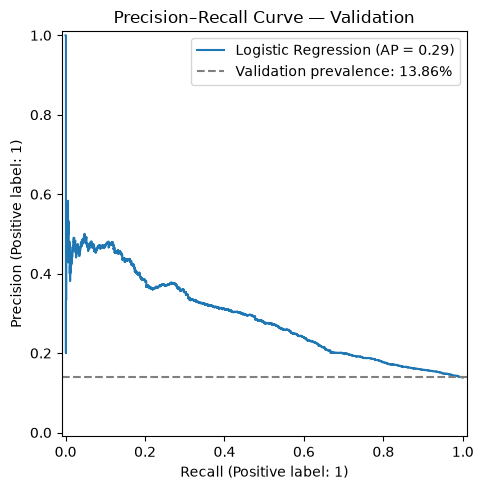

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
PrecisionRecallDisplay.from_predictions(
    y_valid,
    y_valid_score,
    name="Logistic Regression",
    ax=ax,
)
ax.axhline(
    validation_prevalence,
    color="gray",
    linestyle="--",
    label=f"Validation prevalence: {validation_prevalence:.2%}",
)
ax.set_title("Precision–Recall Curve — Validation")
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 Results & Interpretation

The sentinel-aware Logistic Regression reaches Validation AP `0.288234` and
ROC-AUC `0.688023`. AP is well above the 13.86% Validation prevalence reference,
so the scores concentrate subscribers toward the top of the ranking. ROC-AUC
indicates useful but still moderate separation between the two classes.

At the top 5%, the model selects 412 records and captures 179 subscribers.
Precision is 43.45%, Recall is 15.67%, and Lift is 3.13. At the top 10%, it
selects 824 records and captures 309 subscribers, producing 37.50% Precision,
27.06% Recall, and 2.71 Lift. Expanding capacity to 20% captures 499 subscribers
and raises Recall to 43.70%, while Precision and Lift fall to 30.28% and 2.18.

This is the expected ranking trade-off: a larger contact pool captures more
subscribers but becomes less concentrated. None of these capacities is an
operational recommendation because contact costs, benefits, and customer-level
constraints are unavailable.

Train prevalence is 5.57%, compared with 13.86% in Validation. Because AP and
Precision@K depend on prevalence, these results describe this later validation
period and should not be treated as stable across all future campaigns.

## 5. Baseline Summary

| Component | Configuration |
|---|---|
| Model | `LogisticRegression(max_iter=1000)` |
| Ordinary numerical features | Eight features with `StandardScaler` |
| `pdays` | Previous-contact indicator plus elapsed days, then scaling |
| Categorical features | Ten features with `OneHotEncoder(handle_unknown="ignore")` |
| Raw modeling inputs | 19 predictors, excluding `duration` |
| Transformed features | 62 |

| Validation metric | Result |
|---|---:|
| Average Precision | 0.288234 |
| ROC-AUC | 0.688023 |
| Precision@10% | 0.375000 |
| Recall@10% | 0.270578 |
| Lift@10% | 2.705123 |

All learned preprocessing and model parameters were fitted on Train. Validation
was used only for evaluation, and Test remains untouched.

The earlier raw-`pdays` baseline recorded AP `0.297231`, so the sentinel-aware
representation is lower by `0.008997`. The revised baseline nevertheless
preserves the semantic distinction between a sentinel and elapsed days, which
is now a project constraint rather than a Validation-selected option. Model
experiments must be rerun from this new reference.

The model ranks historical subscription outcomes; it does not estimate causal
contact effects, profitability, or calibrated subscription probabilities. A
single chronological Validation period and the material Train/Validation shift
limit claims about future stability.